In [107]:
clear; clc;

## 1.1. Piezoconductivity Equation (Dirichlet)

Solve the 1D piezoconductivity equation: $p_t = \chi p_{xx}$ for $x$ in $[0, \pi]$, $t$ in $[0, 1]$, with initial condition $p(x, 0) = \sin(x)$, boundary conditions $p(0,t) = 0$, $p(\pi,t) = 0$.

### Неявная схема:

In [108]:
format short g

% Параметры
L = pi; t_final = 1;
Nx = 200; Nt = 100;
dx = L / (Nx - 1); dt = t_final / (Nt - 1);
kappa = 1;

% Сетка
x = linspace(0, L, Nx);
t = linspace(0, t_final, Nt);
p_imp = zeros(Nx, Nt);

% Начальное условие
p_imp(:, 1) = sin(x);

% Граничные условия
p_imp(1, :) = 0; p_imp(end, :) = 0;

% Число Куранта
sigma = kappa * (dt / (dx^2))

num_internal = Nx - 2;

main = (1 + 2 * sigma) * ones(num_internal, 1);
sub_diag = -sigma * ones(num_internal - 1, 1);

A = diag(main) + diag(sub_diag, 1) + diag(sub_diag, -1);

for j=1:Nt-1
    p_imp(2:end-1, j+1) = A \ p_imp(2:end-1, j);
end

[X, T] = meshgrid(x, t);
p_exact = (exp(-T) .* sin(X)).';

error_num = sqrt(sum((p_imp(:) - p_exact(:)).^2));
norm_exact = sqrt(sum(p_exact(:).^2));

rel_err = error_num / norm_exact;

disp(rel_err);

sigma = 40.529
0.0021765


In [109]:
size(p_exact)
size(p_imp)

ans =

          200          100

ans =

          200          100



In [110]:
size(X)
size(T)

ans =

          100          200

ans =

          100          200



In [111]:
pairs_list = [X(:), T(:)];
pairs = pairs_list(19990:20000, :);
disp(pairs)

       3.1416      0.89899
       3.1416      0.90909
       3.1416      0.91919
       3.1416      0.92929
       3.1416      0.93939
       3.1416      0.94949
       3.1416       0.9596
       3.1416       0.9697
       3.1416       0.9798
       3.1416       0.9899
       3.1416            1


In [112]:
length(p_exact(:))
length(p_imp(:))

ans = 20000
ans = 20000


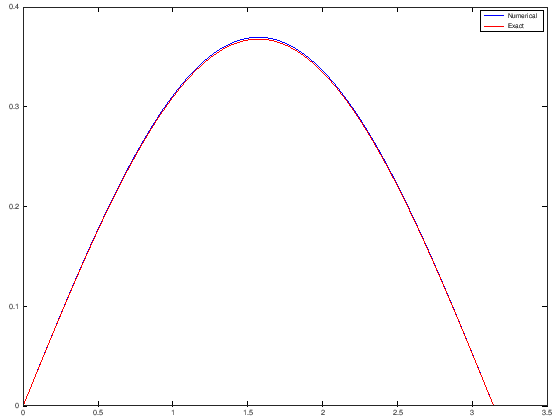

In [113]:
figure;
plot(x, p_imp(:, end), 'b-');
hold on;
p_exact_line = exp(-t_final) * sin(x);
plot(x, p_exact_line, 'r-')
legend('Numerical', 'Exact');

### Явная схема:

In [114]:
format short g

% Параметры
L = pi; t_final = 1;
Nx = 200; Nt = 100;
dx = L / (Nx - 1) 
dt = t_final / (Nt - 1)
kappa = 1;

% Сетка
x = linspace(0, L, Nx);
t = linspace(0, t_final, Nt);
p_exp = zeros(Nx, Nt);

% Начальное условие
p_exp(:, 1) = sin(x);

% Граничные условия
p_exp(1, :) = 0; p_exp(end, :) = 0;

% Критический шаг по времени
dt_crit = 0.5 * (dx^2 / kappa)

% Сколько шагов нужно минимум для устойчивости
num_steps = dt / dt_crit

% Выбираем число подшагов
substeps = 120;

% Актуальный шаг
dt_actual = dt / substeps

% Число Куранта
sigma = kappa * (dt_actual / (dx^2))

for j=1:(Nt-1)
    p_current = p_exp(:, j);
    for s=1:substeps
        p_next = p_current;
        for i=2:(Nx-1)
            p_next(i) = p_current(i) + sigma * (p_current(i-1) - 2 * p_current(i) + p_current(i+1));
        end
        p_current = p_next;
    end
    p_exp(:, j+1) = p_current;
end

[X, T] = meshgrid(x, t);
p_exact = (exp(-T) .* sin(X)).';

error_num = sqrt(sum((p_exp(:) - p_exact(:)).^2));
norm_exact = sqrt(sum(p_exact(:).^2));

rel_err_exp = error_num / norm_exact;

disp(rel_err_exp);

dx = 0.015787
dt = 0.010101
dt_crit = 0.00012461
num_steps = 81.059
dt_actual = 8.4175e-05
sigma = 0.33775
9.1963e-06
